# Crop3Test3: SSIM frente a delta y confianza

Se optimizan únicamente delta, confidence_floor y confidence_scale. Se mantienen la configuración del estudio (100 pruebas, 1000 mezclas, 20 iteraciones, semilla 3333), SSIM como objetivo y los parámetros fijos actuales: alpha_1=-2, alpha_2=-22, gamma=0 y confidence_projection=True.


In [13]:
import importlib
import sys
from pathlib import Path

import numpy as np
import tensorflow as tf
import optuna
import matplotlib.pyplot as plt

project_root = next(
    root for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "project" / "CROP" / "models").is_dir()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from project.loader import Loader
import project.CROP.models.crop3_test as crop3_test_module
import project.CROP.models.crop3_test3 as crop3_test3_module
importlib.reload(crop3_test_module)
importlib.reload(crop3_test3_module)

SEED = 3333
DATASET = "fashion"
CVAE_NAME = "int_256_lat_64_beta_0_4_fashion.keras"
PREDICTOR_NAME = f"CCE_Conv2D_{DATASET}.keras"
N_IMAGES = 1000
N_TRIALS = 100
N_VALIDATION_IMAGES = 1000
N_VALIDATION_RUNS = 3
TARGET_METRIC = "ssim"  # Objetivo solicitado para este estudio.
SEPARATION_ITERATIONS = 20
assert TARGET_METRIC in {"acc_both", "ssim", "recon_bpsnr"}

FIXED_PARAMS = {
    'alpha_1': -2.0, 
    'alpha_2': -22.0,
    "bias": 0.22,
    "slope": 22,
    "beta": 1.0,
    "alpha_mix": 0.5,
    "gamma":0,
    "saturation_object_threshold": 0.05,
    'confidence_projection': True, 
}

tf.keras.utils.set_random_seed(SEED)
data = Loader.data(dataset=DATASET)
cvae = Loader.cvae(model_name=CVAE_NAME)
predictor = Loader.predictor(model_name=PREDICTOR_NAME)

# Generador independiente de las semillas del CVAE y de Optuna.
rng = np.random.default_rng(SEED)
idx0 = rng.permutation(len(data["x_train"]))[:N_IMAGES]
idx1 = rng.permutation(len(data["x_train_1"]))[:N_IMAGES]
train_batch = (
    data["x_train"][idx0], data["x_train_1"][idx1],
    data["y_train"][idx0], data["y_train_1"][idx1],
)


def scalar_metric(metrics, key):
    value = metrics[key]
    # Las métricas de calidad devuelven (media, desvío).
    if isinstance(value, (tuple, list)):
        value = value[0]
    return float(value)


def objective(trial):
    params = {
        **FIXED_PARAMS,
        "delta": trial.suggest_float("delta", 0.0, 1.0),
        "confidence_scale": trial.suggest_float("confidence_scale", 1e-4, 1.2, log=True),
        "confidence_floor": trial.suggest_float("confidence_floor", 1e-8, 0.1, log=True),         
        }
    tf.keras.utils.set_random_seed(SEED)
    model = crop3_test3_module.Crop3Test3(cvae=cvae, predictor=predictor)
    metrics = model.unmix(
        *train_batch,
        params=params,
        iterations=SEPARATION_ITERATIONS,
        labels=data["labels"],
        show_image=False,
        show_metrics=False,
    )
    score = scalar_metric(metrics, TARGET_METRIC)
    if not np.isfinite(score):
        raise ValueError(f"Métrica no finita: {TARGET_METRIC}={score}")
    trial.set_user_attr("effective_params", params)
    for key in ("acc_both", "ssim", "recon_bpsnr"):
        trial.set_user_attr(key, scalar_metric(metrics, key))
    return score


Usando fashion como dataset


## Estudio conjunto

Rangos válidos para el modelo: delta entre 0 y 1; confidence_scale entre 1e-4 y 1.2; confidence_floor entre 1e-8 y 0.1. Los dos parámetros de confianza usan escala logarítmica. El estudio se guarda con un nombre nuevo, separado de los anteriores.


In [14]:
from datetime import datetime

output_dir = project_root / "project" / "experiments" / "optim_params" / "results"
output_dir.mkdir(parents=True, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")
study_path = output_dir / f"crop3_test3_delta_confidence_{DATASET}_{TARGET_METRIC}_{run_id}.sqlite3"
study = optuna.create_study(
    direction="maximize",
    storage=f"sqlite:///{study_path}",
    study_name=f"Crop3Test3_delta_confidence_{DATASET}_{TARGET_METRIC}",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
print("Estudio persistente:", study_path, flush=True)
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
best_params = {**FIXED_PARAMS, **study.best_params}
print("Mejor valor:", study.best_value)
print("Parámetros completos:", best_params)


[I 2026-11-18 16:51:34,900] A new study created in RDB with name: Crop3Test3_delta_confidence_fashion_ssim


Estudio persistente: /home/galsan/Desktop/tesis/CROP_1/project/experiments/optim_params/results/crop3_test3_delta_confidence_fashion_ssim_20261118_165134.sqlite3


[I 2026-11-18 16:51:37,828] Trial 0 finished with value: 0.7384217977523804 and parameters: {'delta': 0.7515756072044787, 'confidence_scale': 0.0002790331190363006, 'confidence_floor': 2.5284184655182513e-05}. Best is trial 0 with value: 0.7384217977523804.
[I 2026-11-18 16:51:40,813] Trial 1 finished with value: 0.7331917881965637 and parameters: {'delta': 0.4998311777480342, 'confidence_scale': 0.04791492189948057, 'confidence_floor': 4.47912289719929e-07}. Best is trial 0 with value: 0.7384217977523804.
[I 2026-11-18 16:51:43,912] Trial 2 finished with value: 0.7191455960273743 and parameters: {'delta': 0.6127948906605941, 'confidence_scale': 0.0003076690708542542, 'confidence_floor': 0.0009669768488733188}. Best is trial 0 with value: 0.7384217977523804.
[I 2026-11-18 16:51:46,976] Trial 3 finished with value: 0.7166842222213745 and parameters: {'delta': 0.37256054205032785, 'confidence_scale': 0.013823718997231367, 'confidence_floor': 6.966418869681592e-07}. Best is trial 0 with v

Mejor valor: 0.7493364810943604
Parámetros completos: {'alpha_1': -2.0, 'alpha_2': -22.0, 'bias': 0.22, 'slope': 22, 'beta': 1.0, 'alpha_mix': 0.5, 'gamma': 0, 'saturation_object_threshold': 0.05, 'confidence_projection': True, 'delta': 0.6529840177372809, 'confidence_scale': 0.01664245987391844, 'confidence_floor': 0.01007748890659532}


## Gráficos con plot_slice

SSIM frente a delta, confidence_floor y confidence_scale usando plot_slice de Optuna. Los puntos provienen de la optimización conjunta.


/tmp/ipykernel_1160627/4029734464.py:3: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study, target_name="SSIM")


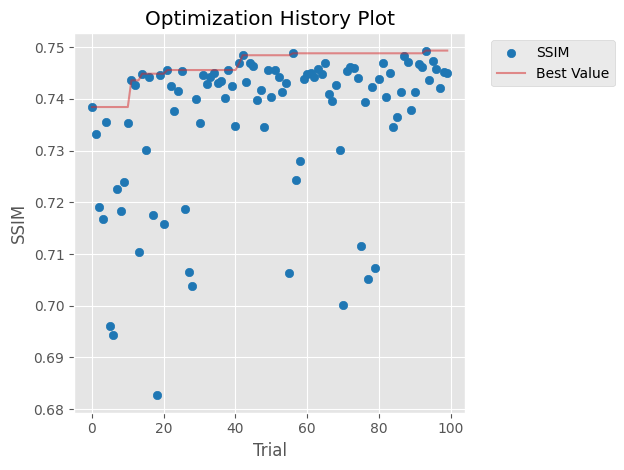

/tmp/ipykernel_1160627/4029734464.py:10: ExperimentalWarning: plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plot_slice(study, params=["delta", "confidence_floor", "confidence_scale"], target_name="SSIM")
/tmp/ipykernel_1160627/4029734464.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


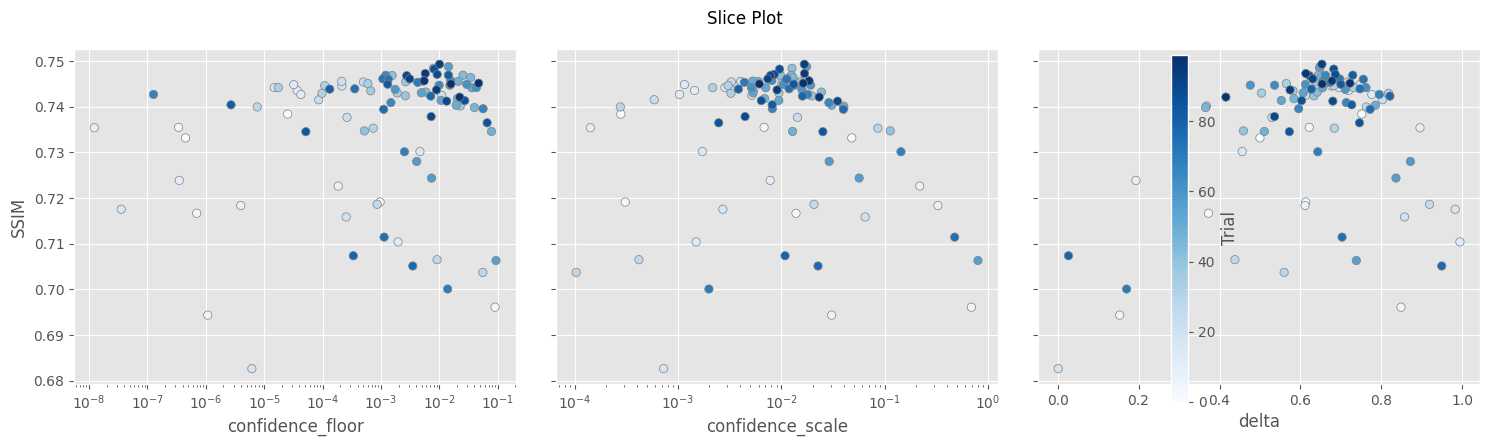

In [15]:
from optuna.visualization.matplotlib import plot_slice, plot_optimization_history

ax = plot_optimization_history(study, target_name="SSIM")
ax.figure.tight_layout()
ax.figure.savefig(output_dir / f"optimization_history_{run_id}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(ax.figure)

# Un panel por parámetro con la implementación plot_slice de Optuna.
axes = plot_slice(study, params=["delta", "confidence_floor", "confidence_scale"], target_name="SSIM")
fig = np.asarray(axes).flat[0].figure
fig.set_size_inches(15, 4.5)
fig.tight_layout()
fig.savefig(output_dir / f"plot_slice_delta_confidence_{run_id}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)


## Validación de Crop3Test3

Evalúa los mejores parámetros en tres mezclas de test independientes; muestra curvas e imágenes de la primera corrida.


In [ ]:
best_params = {**FIXED_PARAMS, **study.best_params}
validation_results = []
validation_rng = np.random.default_rng(SEED + 1000)
for run in range(N_VALIDATION_RUNS):
    idx0 = validation_rng.permutation(len(data["x_test"]))[:N_VALIDATION_IMAGES]
    idx1 = validation_rng.permutation(len(data["x_test_1"]))[:N_VALIDATION_IMAGES]
    tf.keras.utils.set_random_seed(SEED + 1000 + run)
    validation_model = crop3_test3_module.Crop3Test3(cvae=cvae, predictor=predictor)
    metrics = validation_model.unmix(
        data["x_test"][idx0], data["x_test_1"][idx1],
        data["y_test"][idx0], data["y_test_1"][idx1],
        params=best_params.copy(),
        iterations=SEPARATION_ITERATIONS,
        labels=data["labels"],
        # Mostrar una grilla de 1000 imagenes seria ilegible. Las imagenes
        # de la primera corrida se muestran abajo con un subconjunto.
        show_image=False,
        show_metrics=False,
        show_all_curves=(run == 0),
    )
    validation_results.append({
        "run": run + 1,
        **{key: scalar_metric(metrics, key) for key in ("acc_both", "ssim", "recon_bpsnr")},
    })
    print(validation_results[-1])
    if run == 0:
        first_validation_model = validation_model
        first_validation_indices = (idx0, idx1)

# Mostrar solo 10 mezclas de la primera corrida, con sus labels finales.
from project.helper.graphics.graphics import Graphics
m = first_validation_model
idx0, idx1 = first_validation_indices
limit = min(10, len(idx0), len(idx1))
Graphics.complete_plot(
    tf.convert_to_tensor(m.mixed_input[:limit]),
    tf.convert_to_tensor(data["x_test"][idx0[:limit]]),
    tf.convert_to_tensor(data["x_test_1"][idx1[:limit]]),
    data["y_test"][idx0[:limit]], data["y_test_1"][idx1[:limit]],
    tf.convert_to_tensor(m.source1_estimation[:limit]),
    tf.convert_to_tensor(m.source2_estimation[:limit]),
    tf.convert_to_tensor(m.mask1[:limit]), tf.convert_to_tensor(m.mask2[:limit]),
    m.predictions1[:limit], m.predictions2[:limit],
    tf.convert_to_tensor(m.source1_estimation[:limit]),
    model_params=best_params,
    class_labels=data["labels"],
)


## Resultados de validación

In [ ]:
validation_summary = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, key in zip(axes, ("acc_both", "ssim", "recon_bpsnr")):
    values = np.array([row[key] for row in validation_results])
    validation_summary[key] = {"mean": float(values.mean()), "std": float(values.std())}
    ax.plot(np.arange(1, len(values) + 1), values, "o-")
    ax.axhline(values.mean(), color="tab:orange", linestyle="--")
    ax.set_title(f"{key}: {values.mean():.4f} ± {values.std():.4f}")
    ax.set_xlabel("Corrida de validación")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
plt.close(fig)
print(validation_summary)


## Guardar estudio y resultados

Guarda parámetros completos, todas las pruebas y validación en un archivo pickle; no guarda batches de imágenes.

In [ ]:
import pickle
from datetime import datetime

output_dir = project_root / "project" / "experiments" / "optim_params" / "results"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"crop3_test3_delta_confidence_{DATASET}_{TARGET_METRIC}_{datetime.now():%Y%m%d_%H%M%S}.pkl"
with output_path.open("wb") as stream:
    pickle.dump({
        "model": "Crop3Test3",
        "dataset": DATASET,
        "cvae": CVAE_NAME,
        "predictor": PREDICTOR_NAME,
        "seed": SEED,
        "objective": TARGET_METRIC,
        "best_params": best_params,
        "study": study,
        "validation_results": validation_results,
        "validation_summary": validation_summary,
    }, stream)
print("Guardado:", output_path)
